# 03 · Líneas base y modelos candidatos

Todos los modelos usan **la misma preparación** (`src/pipeline.py`), **la misma validación** y **la misma métrica**:

- **Validación:** `CVTemporalSubmuestreada`: `TimeSeriesSplit(3)` sobre entrenamiento (ene-2019 a jun-2020), con las filas ordenadas por tiempo.
  - Cada pliegue se **ajusta** con todos los fraudes y el 5 % de las legítimas, y se **valida** con todas las filas del pliegue siguiente, a la prevalencia real.
  - **¿Por qué no `GroupKFold` por cliente?** El banco puntúa transacciones de **sus propios tarjetahabientes**, ya conocidos: en producción, el cliente sí tuvo transacciones en el pasado. Separar por cliente simularía clientes nuevos, que no es el caso de uso. Lo que sí hay que respetar es el **tiempo**, para no predecir el pasado con el futuro.
- **Métrica técnica:** AUC-PR (`average_precision`).
  - En entrenamiento se pondera a la prevalencia real (las legítimas pesan 1/0,05), para que la **brecha** mida sobreajuste y no la diferencia de prevalencia.
- **Métrica de negocio:** pérdida neta = monto de fraude no detectado + USD 5 por falsa alarma.
  - Se calcula con las predicciones fuera de pliegue, en el umbral que la minimiza.

Cada corrida queda en MLflow con parámetros, semilla, datos (tabla, fecha de corte, hash), métricas, tags (fase, familia, commit) y el pipeline entrenado con firma y ejemplo de entrada.

In [1]:
import sys, json, time, hashlib, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import mlflow
from IPython.display import Image, display
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

from datos import cargar_obt, metadatos_snapshot
from pipeline import (SEMILLA, ReglasFijas, construir_modelo, dividir, CVTemporalSubmuestreada, auc_pr,
                      perdida_neta, MontoSobreP95Categoria)
from experimento import configurar_mlflow, borrar_corridas, correr_modelo, etiquetar, registrar_datos, commit_git

DOCS = Path.cwd().parent / "docs" / "modelos"
DOCS.mkdir(parents=True, exist_ok=True)
def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(DOCS / nombre, dpi=120); plt.close(fig)
    display(Image(filename=str(DOCS / nombre)))

print("MLflow:", configurar_mlflow(), "| commit:", commit_git())
print("corridas previas de este notebook borradas:", borrar_corridas(["baseline", "candidato"]))
meta = metadatos_snapshot(); print("snapshot:", meta["fecha_corte_snapshot"], meta["sha256"][:12])
df = cargar_obt()
X_ent, y_ent, X_pru, y_pru, ent, pru = dividir(df)
monto_ent = ent["amt"].to_numpy()
cv = CVTemporalSubmuestreada()
print("entrenamiento:", X_ent.shape, f"fraude {100*y_ent.mean():.3f} %")

MLflow: http://127.0.0.1:5055 | commit: d430a61-con-cambios
corridas previas de este notebook borradas: 0
snapshot: 2026-11-18 14:52:45.511 -0800 9be410f73fb8


entrenamiento: (1326733, 21) fraude 0.576 %


## 1. Líneas base

1. **Ingenua:** `DummyClassifier(strategy="prior")`, que asigna a todos la misma probabilidad (la prevalencia). Su AUC-PR es aproximadamente la prevalencia.
2. **De negocio:** las **reglas fijas actuales** del PSet 1 (`ReglasFijas` en `src/pipeline.py`). Alerta si se cumple al menos una:
   - monto > p95 de su categoría (aprendido en el ajuste);
   - compra entre 22:00 y 03:59 con monto ≥ USD 100. El PSet 1 decía "sobre un monto mínimo"; los USD 100 son un supuesto que se documenta;
   - comercio a más de 100 km del domicilio del cliente.

Las reglas no generan un ranking (su puntaje es 0 o 1), así que su AUC-PR es la de un único punto de corte.

In [2]:
resultados = []
resultados.append(correr_modelo("dummy_prior", "ingenuo", "baseline", construir_modelo(DummyClassifier(strategy="prior")),
                                X_ent, y_ent, monto_ent, cv))
resultados.append(correr_modelo("reglas_fijas_pset1", "reglas_de_negocio", "baseline", ReglasFijas(), X_ent, y_ent, monto_ent, cv,
                                params={"regla_monto": "amt > p95 categoría", "regla_nocturna": "22:00-03:59 y amt >= 100",
                                        "regla_distancia": "distancia_km > 100"}))
for r in resultados:
    print(f"{r['nombre']:22s} AUC-PR CV {r['cv_auc_pr_media']:.4f} ± {r['cv_auc_pr_std']:.4f} | pérdida neta OOF ${r['cv_perdida_neta_oof']:,.0f} | run {r['run_id']}")

2026/11/18 23:19:39 INFO mlflow.tracking._tracking_service.client: 🏃 View run dummy_prior at: http://127.0.0.1:5055/#/experiments/1/runs/49ed9da1659e4f278acbc695d950fa09.


2026/11/18 23:19:39 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://127.0.0.1:5055/#/experiments/1.


2026/11/18 23:19:42 INFO mlflow.tracking._tracking_service.client: 🏃 View run reglas_fijas_pset1 at: http://127.0.0.1:5055/#/experiments/1/runs/64a2bc2d3667483f8e1647c29c6ae065.


2026/11/18 23:19:42 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://127.0.0.1:5055/#/experiments/1.


dummy_prior            AUC-PR CV 0.0053 ± 0.0005 | pérdida neta OOF $2,842,810 | run 49ed9da1659e4f278acbc695d950fa09
reglas_fijas_pset1     AUC-PR CV 0.0123 ± 0.0014 | pérdida neta OOF $1,661,011 | run 64a2bc2d3667483f8e1647c29c6ae065


## 2. Cinco familias de modelos con hiperparámetros por defecto

| Familia | Modelo | Nota |
|---|---|---|
| Lineal regularizado | `LogisticRegression` (L2, C=1) | `max_iter=1000` para que converja; lo demás por defecto |
| Bagging | `RandomForestClassifier` | `n_jobs=-1` solo para usar los 4 núcleos |
| Boosting | `HistGradientBoostingClassifier` | Por defecto (`learning_rate=0.1`) |
| Red neuronal | `MLPClassifier` | Por defecto (100 neuronas ocultas, Adam, `learning_rate_init=0.001`) |
| State of the art | **LLM (Gemini) por prompting** | Sección 3: no se entrena; se evalúa sobre una muestra pequeña |

Todos usan `random_state=42`.

In [3]:
candidatos = {
    "logistic_regression": ("lineal_regularizado", LogisticRegression(max_iter=1000, random_state=SEMILLA), None),
    "random_forest": ("bagging", RandomForestClassifier(n_jobs=-1, random_state=SEMILLA), None),
    "hist_gradient_boosting": ("boosting", HistGradientBoostingClassifier(random_state=SEMILLA), 0.1),
    "mlp": ("red_neuronal", MLPClassifier(random_state=SEMILLA), 0.001),
}
for nombre, (familia, est, lr) in candidatos.items():
    t0 = time.perf_counter()
    r = correr_modelo(nombre, familia, "candidato", construir_modelo(est), X_ent, y_ent, monto_ent, cv,
                      params={"learning_rate": lr if lr is not None else "no aplica"})
    r["learning_rate"] = lr
    resultados.append(r)
    print(f"{nombre:24s} AUC-PR CV {r['cv_auc_pr_media']:.4f} ± {r['cv_auc_pr_std']:.4f} | entren. {r['entrenamiento_auc_pr_media']:.4f} "
          f"| brecha {r['brecha_auc_pr']:+.4f} | {time.perf_counter()-t0:.0f} s | run {r['run_id']}")

2026/11/18 23:19:51 INFO mlflow.tracking._tracking_service.client: 🏃 View run logistic_regression at: http://127.0.0.1:5055/#/experiments/1/runs/cae3bfbbe39947cd8595e326d614c06a.


2026/11/18 23:19:51 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://127.0.0.1:5055/#/experiments/1.


logistic_regression      AUC-PR CV 0.4960 ± 0.0174 | entren. 0.5259 | brecha +0.0299 | 8 s | run cae3bfbbe39947cd8595e326d614c06a


2026/11/18 23:20:09 INFO mlflow.tracking._tracking_service.client: 🏃 View run random_forest at: http://127.0.0.1:5055/#/experiments/1/runs/7c39d1063bde43e295f5a48a99c9505e.


2026/11/18 23:20:09 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://127.0.0.1:5055/#/experiments/1.


random_forest            AUC-PR CV 0.9406 ± 0.0202 | entren. 1.0000 | brecha +0.0594 | 18 s | run 7c39d1063bde43e295f5a48a99c9505e


... (2 outputs left out)

hist_gradient_boosting   AUC-PR CV 0.9612 ± 0.0163 | entren. 0.9980 | brecha +0.0368 | 26 s | run fb65308c5c97454c9567082b30206b3c


2026/11/18 23:22:14 INFO mlflow.tracking._tracking_service.client: 🏃 View run mlp at: http://127.0.0.1:5055/#/experiments/1/runs/efc4fbf08527471ab0b4335e715728df.


2026/11/18 23:22:14 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://127.0.0.1:5055/#/experiments/1.


mlp                      AUC-PR CV 0.9177 ± 0.0233 | entren. 1.0000 | brecha +0.0823 | 99 s | run efc4fbf08527471ab0b4335e715728df


In [4]:
cols = ["nombre", "familia", "fase", "entrenamiento_auc_pr_media", "cv_auc_pr_media", "cv_auc_pr_std", "brecha_auc_pr",
        "learning_rate", "segundos_entrenamiento", "segundos_prediccion", "final_segundos_entrenamiento",
        "cv_perdida_neta_oof", "cv_umbral_optimo", "run_id"]
tabla = pd.DataFrame([{c: r.get(c) for c in cols} for r in resultados])
reglas_perdida = tabla.loc[tabla["nombre"] == "reglas_fijas_pset1", "cv_perdida_neta_oof"].item()
tabla["supera_dummy"] = tabla["cv_auc_pr_media"] > tabla.loc[tabla["nombre"] == "dummy_prior", "cv_auc_pr_media"].item()
tabla["supera_reglas_auc_pr"] = tabla["cv_auc_pr_media"] > tabla.loc[tabla["nombre"] == "reglas_fijas_pset1", "cv_auc_pr_media"].item()
tabla["reduccion_perdida_vs_reglas_pct"] = 100 * (1 - tabla["cv_perdida_neta_oof"] / reglas_perdida)
tabla["diagnostico"] = np.select(
    [tabla["fase"] == "baseline", tabla["brecha_auc_pr"] > 0.05, tabla["entrenamiento_auc_pr_media"] < 0.7],
    ["línea base", "sobreajuste (brecha > 0,05)", "subajuste (entrenamiento bajo)"], "ajuste razonable")
tabla.to_csv(DOCS / "resultados_baseline_candidatos.csv", index=False)
tabla.drop(columns=["run_id"]).round(4)

,nombre,familia,fase,entrenamiento_auc_pr_media,cv_auc_pr_media,cv_auc_pr_std,brecha_auc_pr,learning_rate,segundos_entrenamiento,segundos_prediccion,final_segundos_entrenamiento,cv_perdida_neta_oof,cv_umbral_optimo,supera_dummy,supera_reglas_auc_pr,reduccion_perdida_vs_reglas_pct,diagnostico
0,dummy_prior,ingenuo,baseline,0.0062,0.0053,0.0005,0.0009,NaN,0.3306,1.5733,0.2473,2842809.94,inf,False,False,-71.1494,línea base
1,reglas_fijas_pset1,reglas_de_negocio,baseline,0.0138,0.0123,0.0014,0.0015,NaN,0.0330,0.0815,0.0205,1661010.99,1.0000,True,False,0.0000,línea base
2,logistic_regression,lineal_regularizado,candidato,0.5259,0.4960,0.0174,0.0299,NaN,2.0046,1.6902,0.8517,210610.65,0.1621,True,True,87.3203,subajuste (entrenamiento bajo)
3,random_forest,bagging,candidato,1.0000,0.9406,0.0202,0.0594,NaN,6.2207,3.1035,4.6977,37420.48,0.4400,True,True,97.7471,"sobreajuste (brecha > 0,05)"
4,hist_gradient_boosting,boosting,candidato,0.9980,0.9612,0.0163,0.0368,0.100,5.6442,12.5589,3.4023,34324.81,0.2400,True,True,97.9335,ajuste razonable
5,mlp,red_neuronal,candidato,1.0000,0.9177,0.0233,0.0823,0.001,52.1584,2.2829,41.1323,67201.63,0.0462,True,True,95.9542,"sobreajuste (brecha > 0,05)"


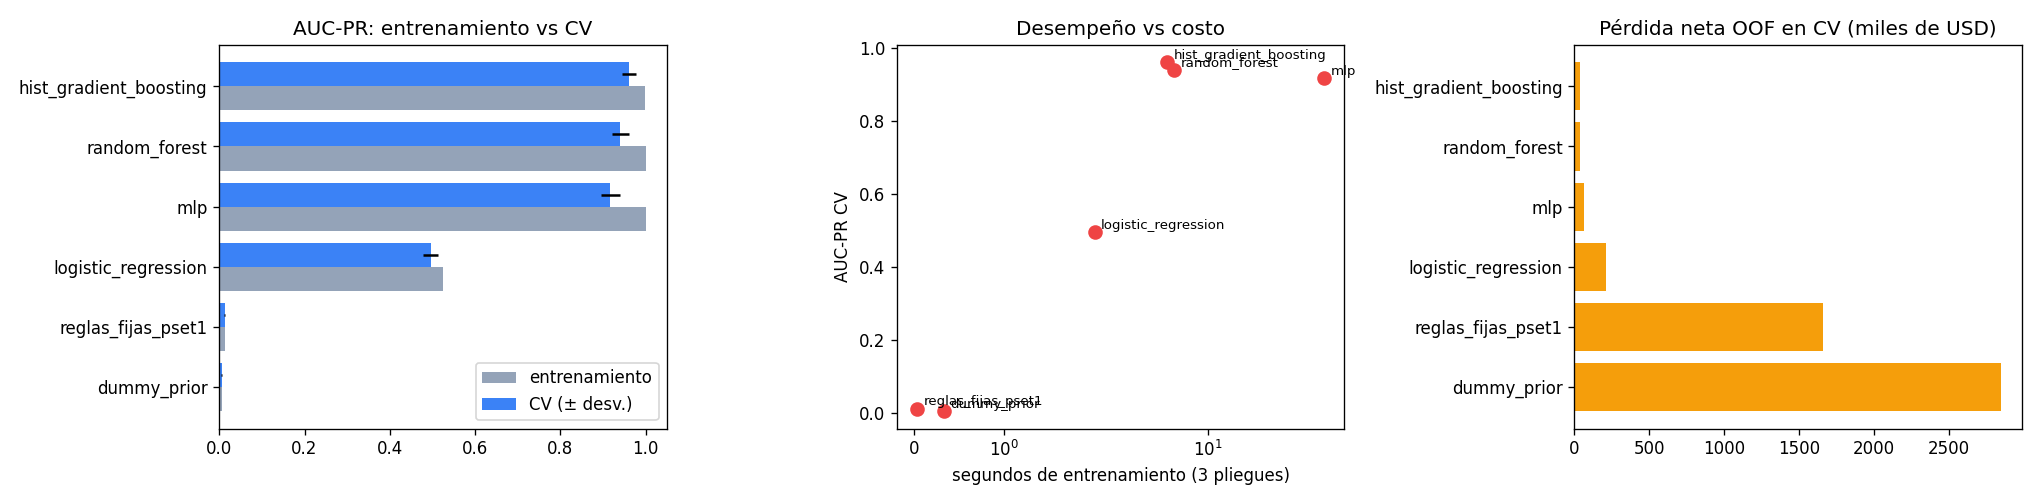

In [5]:
t = tabla.sort_values("cv_auc_pr_media")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
y = np.arange(len(t))
ax[0].barh(y - .2, t["entrenamiento_auc_pr_media"], height=.4, color="#94a3b8", label="entrenamiento")
ax[0].barh(y + .2, t["cv_auc_pr_media"], xerr=t["cv_auc_pr_std"], height=.4, color="#3b82f6", label="CV (± desv.)")
ax[0].set_yticks(y, t["nombre"]); ax[0].legend(loc="lower right"); ax[0].set_title("AUC-PR: entrenamiento vs CV")
ax[1].scatter(t["segundos_entrenamiento"], t["cv_auc_pr_media"], s=60, color="#ef4444")
for _, r in t.iterrows():
    ax[1].annotate(r["nombre"], (r["segundos_entrenamiento"], r["cv_auc_pr_media"]), fontsize=8, xytext=(4, 2), textcoords="offset points")
ax[1].set_xscale("symlog"); ax[1].set_xlabel("segundos de entrenamiento (3 pliegues)"); ax[1].set_ylabel("AUC-PR CV"); ax[1].set_title("Desempeño vs costo")
ax[2].barh(t["nombre"], t["cv_perdida_neta_oof"] / 1e3, color="#f59e0b"); ax[2].set_title("Pérdida neta OOF en CV (miles de USD)")
guardar(fig, "comparacion_baseline_candidatos.png")

## 3. State of the art: LLM por prompting (Gemini)

**Planteamiento:** el LLM no se entrena. Recibe una descripción del problema, unos pocos ejemplos etiquetados (*few-shot*) y un lote de transacciones descritas con las mismas variables que usa el modelo tabular. Devuelve en JSON una probabilidad de fraude por transacción.

**Por qué con una muestra pequeña:**
- La capa gratuita de Google AI Studio limita las solicitudes por minuto y por día.
- Puntuar 1,3 M de filas por API no es viable ni en tiempo ni en costo, y además no cumpliría la latencia de una autorización.
- Por eso el LLM **no puede pasar por la misma CV** que el resto: se evalúa sobre una muestra del **último pliegue de validación**.

**Comparación justa:** se evalúa sobre las mismas filas que las **predicciones fuera de pliegue** de los modelos tabulares. En ese pliegue, ningún modelo vio esas filas al entrenar. Los ejemplos few-shot salen del bloque de ajuste de ese mismo pliegue (fechas anteriores).

**Privacidad:** los datos son sintéticos (Sparkov, CC0) y solo se envían variables numéricas y categóricas, sin nombres ni identificadores.

In [6]:
from google import genai
from google.genai import types

ENV = dict(l.split("=", 1) for l in (Path.cwd().parent / ".env").read_text().splitlines() if "=" in l and not l.startswith("#"))
CLAVE, MODELO_LLM = ENV.get("GEMINI_API_KEY", "").strip(), ENV.get("GEMINI_MODEL", "gemini-3.5-flash-lite").strip()
assert CLAVE and CLAVE != "clave_ficticia", "Falta GEMINI_API_KEY en pset_3/.env"
# Sin reintentos ocultos del SDK (los hace llamar(), con registro de cada espera) y 60 s de límite por solicitud.
cliente = genai.Client(api_key=CLAVE, http_options=types.HttpOptions(timeout=60_000, retry_options=types.HttpRetryOptions(attempts=1)))
MODELOS = [MODELO_LLM] + [m for m in ["gemini-3.5-flash-lite", "gemini-3.1-flash-lite"] if m != MODELO_LLM]

# Último pliegue: bloque de ajuste (para los ejemplos) y bloque de validación (para evaluar)
ajuste, valid = list(cv.split(X_ent, y_ent))[-1]
rng = np.random.default_rng(SEMILLA)
valid_fr, valid_le = valid[y_ent.values[valid] == 1], valid[y_ent.values[valid] == 0]
N_FRAUDE, N_LEGIT, LOTE = 24, 96, 24
muestra = np.sort(np.concatenate([rng.choice(valid_fr, N_FRAUDE, replace=False), rng.choice(valid_le, N_LEGIT, replace=False)]))
muestra = rng.permutation(muestra)
aj_fr, aj_le = ajuste[y_ent.values[ajuste] == 1], ajuste[y_ent.values[ajuste] == 0]
ejemplos = np.concatenate([rng.choice(aj_fr, 4, replace=False), rng.choice(aj_le, 4, replace=False)])

p95 = MontoSobreP95Categoria().fit(X_ent.iloc[ajuste][["amt", "categoria"]])
VARS = ["amt", "categoria", "hora", "es_nocturna", "distancia_km", "edad_en_transaccion", "n_tx_1h", "gasto_1h",
        "n_tx_24h", "gasto_24h", "segundos_desde_anterior", "monto_relativo"]
def describir(i):
    fila = X_ent.iloc[i]
    d = {v: (round(float(fila[v]), 2) if isinstance(fila[v], (int, float, np.number)) and not isinstance(fila[v], (bool, np.bool_)) else (bool(fila[v]) if isinstance(fila[v], (bool, np.bool_)) else fila[v])) for v in VARS}
    d["amt_sobre_p95_categoria"] = round(float(p95.transform(X_ent.iloc[[i]][["amt", "categoria"]])[0, 0]), 2)
    return d

SISTEMA = ('Eres un analista de fraude con tarjeta de crédito. Para cada transacción estima la probabilidad de que sea '
           'fraude (entre 0 y 1). Variables: amt (USD), categoria del comercio, hora (0-23), es_nocturna (22:00-03:59), '
           'distancia_km cliente-comercio, edad del titular, n_tx_1h/gasto_1h y n_tx_24h/gasto_24h (transacciones y '
           'gasto del mismo cliente en la hora y 24 h previas), segundos_desde_anterior, monto_relativo (monto / '
           'promedio previo del cliente) y amt_sobre_p95_categoria (monto / percentil 95 de su categoría). '
           'Responde SOLO con JSON: una lista de objetos {"id": <id>, "prob_fraude": <número>} con el mismo orden.')
ejemplos_txt = "\n".join(json.dumps({**describir(i), "es_fraude": int(y_ent.values[i])}, ensure_ascii=False) for i in ejemplos)
def prompt_lote(ids):
    tx = "\n".join(json.dumps({"id": int(k), **describir(i)}, ensure_ascii=False) for k, i in ids)
    return f"Ejemplos etiquetados:\n{ejemplos_txt}\n\nTransacciones a puntuar:\n{tx}"

prompt_hash = hashlib.sha256((SISTEMA + ejemplos_txt).encode()).hexdigest()[:16]
print(f"Modelo: {MODELO_LLM} | muestra: {len(muestra)} filas ({N_FRAUDE} fraudes, prevalencia {N_FRAUDE/len(muestra):.0%}) | lotes de {LOTE}")

Modelo: gemini-3.5-flash-lite | muestra: 120 filas (24 fraudes, prevalencia 20%) | lotes de 24


In [7]:
modelos_usados = []
def llamar(texto, intentos=4):
    espera = 15
    for k in range(intentos):
        modelo = MODELOS[min(k // 2, len(MODELOS) - 1)]   # 2 intentos con el principal, luego el alternativo
        try:
            cfg = types.GenerateContentConfig(system_instruction=SISTEMA, temperature=0, response_mime_type="application/json")
            r = cliente.models.generate_content(model=modelo, contents=texto, config=cfg)
            modelos_usados.append(modelo)
            return json.loads(r.text), r.usage_metadata
        except Exception as e:                       # 429 (cuota gratuita), 503/504 (demanda) u otra falla transitoria
            print(f"  intento {k+1} ({modelo}): {type(e).__name__}: {str(e)[:110]} -> espero {espera} s")
            time.sleep(espera); espera *= 2
    raise RuntimeError("El LLM no respondió tras varios intentos")

t0 = time.perf_counter()
pred_llm, solicitudes, tokens = {}, 0, 0
for a in range(0, len(muestra), LOTE):
    ids = [(a + j, i) for j, i in enumerate(muestra[a:a + LOTE])]
    salida, uso = llamar(prompt_lote(ids))
    solicitudes += 1; tokens += (uso.total_token_count or 0) if uso else 0
    for o in salida:
        pred_llm[int(o["id"])] = float(o["prob_fraude"])
    print(f"lote {a//LOTE + 1}: {len(salida)} respuestas")
    time.sleep(7)                                    # ~8 solicitudes/min como máximo: dentro de la capa gratuita
seg_llm = time.perf_counter() - t0
score_llm = np.array([pred_llm.get(k, np.nan) for k in range(len(muestra))])
print(f"{solicitudes} solicitudes, {tokens} tokens, {seg_llm:.0f} s; respuestas faltantes: {int(np.isnan(score_llm).sum())}; modelos: {sorted(set(modelos_usados))}")

lote 1: 24 respuestas


lote 2: 24 respuestas


lote 3: 24 respuestas


lote 4: 24 respuestas


lote 5: 24 respuestas


5 solicitudes, 31167 tokens, 43 s; respuestas faltantes: 0; modelos: ['gemini-3.5-flash-lite']


In [8]:
y_m = y_ent.values[muestra]
score_llm_ok = np.nan_to_num(score_llm, nan=float(np.nanmedian(score_llm)))
comp = {"llm_gemini": auc_pr(y_m, score_llm_ok)}
pos = {i: k for k, i in enumerate(resultados[0]["oof_indices"])}
for r in resultados:
    if r["fase"] == "candidato" or r["nombre"] == "reglas_fijas_pset1":
        oof = pd.Series(r["oof_score"], index=r["oof_indices"])
        comp[r["nombre"]] = auc_pr(y_m, oof.loc[muestra].to_numpy())
comp_df = pd.DataFrame({"auc_pr_en_muestra": comp}).sort_values("auc_pr_en_muestra", ascending=False)
comp_df["nota"] = f"{len(muestra)} filas del último pliegue de validación, prevalencia {y_m.mean():.0%} (no comparable con la CV a prevalencia real)"
comp_df.to_csv(DOCS / "llm_vs_tabulares_misma_muestra.csv")
pd.DataFrame({"fila_obt": muestra, "is_fraud": y_m, "prob_llm": score_llm}).to_csv(DOCS / "llm_predicciones_muestra.csv", index=False)

with mlflow.start_run(run_name="llm_gemini_prompting") as run:
    etiquetar("candidato", "state_of_the_art_llm", evaluacion="muestra del último pliegue (no CV completa)")
    registrar_datos()
    mlflow.log_params({"llm_modelo": MODELO_LLM, "llm_modelos_usados": ",".join(sorted(set(modelos_usados))), "llm_temperatura": 0, "llm_ejemplos_few_shot": len(ejemplos),
                       "llm_muestra_filas": len(muestra), "llm_muestra_fraudes": N_FRAUDE, "llm_lote": LOTE,
                       "llm_prompt_sha256_16": prompt_hash})
    mlflow.log_metrics({"muestra_auc_pr_llm": comp["llm_gemini"], "segundos_inferencia": seg_llm,
                        "llm_solicitudes": solicitudes, "llm_tokens": tokens,
                        "llm_respuestas_faltantes": int(np.isnan(score_llm).sum()),
                        **{f"muestra_auc_pr_{k}": v for k, v in comp.items() if k != "llm_gemini"}})
    mlflow.log_text(SISTEMA + "\n\n" + prompt_lote([(0, muestra[0])]), "prompt_ejemplo.txt")
    mlflow.log_artifact(str(DOCS / "llm_predicciones_muestra.csv"))
    run_llm = run.info.run_id
print("run LLM:", run_llm)
comp_df

2026/11/18 23:22:59 INFO mlflow.tracking._tracking_service.client: 🏃 View run llm_gemini_prompting at: http://127.0.0.1:5055/#/experiments/1/runs/84e641c8ea644c3887d6f5006f4e3c01.


2026/11/18 23:22:59 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://127.0.0.1:5055/#/experiments/1.


run LLM: 84e641c8ea644c3887d6f5006f4e3c01


,auc_pr_en_muestra,nota
random_forest,0.998333,"120 filas del último pliegue de validación, pr..."
hist_gradient_boosting,0.998333,"120 filas del último pliegue de validación, pr..."
mlp,0.989369,"120 filas del último pliegue de validación, pr..."
llm_gemini,0.961929,"120 filas del último pliegue de validación, pr..."
logistic_regression,0.915584,"120 filas del último pliegue de validación, pr..."
reglas_fijas_pset1,0.332008,"120 filas del último pliegue de validación, pr..."


## 4. Diagnóstico y los 3 mejores para el tuning

- **Sobreajuste o subajuste:** se diagnostica con la brecha entre la AUC-PR de entrenamiento (ponderada a la prevalencia real) y la de CV, y con el nivel de entrenamiento.
- **Selección para el tuning:** los 3 mejores por **AUC-PR media en CV** entre los candidatos tabulares. El LLM queda fuera: no se evaluó con la misma CV y no se puede ajustar con una búsqueda de hiperparámetros.

In [9]:
cand = tabla[tabla["fase"] == "candidato"].sort_values("cv_auc_pr_media", ascending=False)
top3 = cand.head(3)[["nombre", "familia", "cv_auc_pr_media", "cv_auc_pr_std", "run_id"]]
(DOCS / "top3_para_tuning.json").write_text(top3.to_json(orient="records", indent=2, force_ascii=False), encoding="utf-8")
for _, r in tabla.iterrows():
    print(f"{r['nombre']:24s} {r['diagnostico']:32s} | supera dummy: {r['supera_dummy']} | supera reglas: {r['supera_reglas_auc_pr']} "
          f"| pérdida vs reglas: {r['reduccion_perdida_vs_reglas_pct']:+.1f} %")
top3

dummy_prior              línea base                       | supera dummy: False | supera reglas: False | pérdida vs reglas: -71.1 %
reglas_fijas_pset1       línea base                       | supera dummy: True | supera reglas: False | pérdida vs reglas: +0.0 %
logistic_regression      subajuste (entrenamiento bajo)   | supera dummy: True | supera reglas: True | pérdida vs reglas: +87.3 %
random_forest            sobreajuste (brecha > 0,05)      | supera dummy: True | supera reglas: True | pérdida vs reglas: +97.7 %
hist_gradient_boosting   ajuste razonable                 | supera dummy: True | supera reglas: True | pérdida vs reglas: +97.9 %
mlp                      sobreajuste (brecha > 0,05)      | supera dummy: True | supera reglas: True | pérdida vs reglas: +96.0 %


,nombre,familia,cv_auc_pr_media,cv_auc_pr_std,run_id
4,hist_gradient_boosting,boosting,0.961244,0.016265,fb65308c5c97454c9567082b30206b3c
3,random_forest,bagging,0.940629,0.020175,7c39d1063bde43e295f5a48a99c9505e
5,mlp,red_neuronal,0.917724,0.023298,efc4fbf08527471ab0b4335e715728df
